# Reproducing the figures
## Optimal Algorithms for Fixed-Graph Multi-Attribution Privacy

This notebook explains the three synthetic experiments and regenerates the figure files used in the paper. Run the cells in order. The first part uses the recorded results supplied with the code, so it is quick to inspect. It also solves one benchmark LP and checks a single traversal of the implemented LP-weighted greedy algorithm. The final section can rerun all three original experiment scripts from their fixed seeds.

Keep this notebook at the repository root, alongside the `code/`, `data/`, and `results/` directories. Install the experiment dependencies with `python -m pip install -r requirements.txt`; install Jupyter with `python -m pip install jupyterlab ipykernel` if needed. Then open the notebook with `python -m jupyterlab reproduce_figures.ipynb` using the same Python environment.

Generated plots go into `notebook_outputs/figures/`. Optional experiment reruns use their own working directory under `notebook_outputs/rerun/`. The supplied scripts, benchmark data, recorded results, and released figures are preserved.

### 1. Locate the code and record the environment

The shared plotting style and algorithm implementation come from the accompanying Python files. The version information below is useful when comparing a new run with the recorded results: the LP solver can choose a different optimal fractional solution in another software environment.

In [1]:
from pathlib import Path
import hashlib
import json
import platform
import shutil
import subprocess
import sys
import time

import numpy as np
import scipy
import matplotlib
from IPython.display import Image, Markdown, display

candidates = [Path.cwd().resolve(), Path.cwd().resolve().parent]
ROOT = next((p for p in candidates
             if (p / "code/multiattr.py").is_file()
             and (p / "data/contribution_bounding_instances.json").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Open this notebook from the repository root.")
CODE = ROOT / "code"
if str(CODE) not in sys.path:
    sys.path.insert(0, str(CODE))

from multiattr import solve_lp, lp_weighted_greedy, greedy_cb, tight_instance
from figstyle import plt, COLORS, save

RESULTS = ROOT / "results"
OUTPUT = ROOT / "notebook_outputs"
FIG = OUTPUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
versions = {"python": platform.python_version(), "numpy": np.__version__,
            "scipy": scipy.__version__, "matplotlib": matplotlib.__version__}
print("Code directory:", CODE.relative_to(ROOT))
print("Notebook outputs:", OUTPUT.relative_to(ROOT))
print("Current versions:", json.dumps(versions, indent=2))
print("Experiment dependency pins:\n" + (ROOT / "requirements.txt").read_text())

def load_json(path):
    return json.loads(Path(path).read_text())

def digest(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def show_table(headers, rows):
    def text(value):
        return str(value).replace("|", r"\|").replace("\n", " ")
    lines = ["| " + " | ".join(map(text, headers)) + " |",
             "| " + " | ".join(["---"] * len(headers)) + " |"]
    lines += ["| " + " | ".join(map(text, row)) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

protected_paths = sorted(
    list(CODE.glob("*.py")) + list((ROOT / "tests").glob("*.py"))
    + [ROOT / "requirements.txt"]
    + list((ROOT / "data").glob("*.json"))
    + list(RESULTS.glob("*.json"))
    + list((ROOT / "figures").glob("*.pdf"))
    + list((ROOT / "figures").glob("*.png")))
original_hashes = {str(p.relative_to(ROOT)): digest(p) for p in protected_paths}

Code directory: code
Notebook outputs: notebook_outputs
Current versions: {
  "python": "3.12.14",
  "numpy": "2.3.5",
  "scipy": "1.17.0",
  "matplotlib": "3.10.8"
}
Experiment dependency pins:
numpy==2.3.5
scipy==1.17.0
matplotlib==3.10.8



### 2. Match the notebook to the paper

| Paper panel | Experiment and question | Regenerated file |
| --- | --- | --- |
| Figure 1(a) | A: How much can the processing order affect ordinary greedy on tight instances? | `expA_r_vs_delta.pdf` (left panel) |
| Figure 1(b) | A: How many examples do ordinary and LP-weighted greedy retain on planted-hub graphs? | `expA_r_vs_delta.pdf` (right panel) |
| Figure 2, left | B: How does the Gaussian noise term vary with network density? | `expB_density_parameter.pdf` |
| Figure 2, right | C: How does the group-based testing error vary with the privacy parameter and number of groups? | `expC_iid_testing.pdf` |

Each PDF is also saved as a PNG for inline viewing. The manuscript places the two Experiment B/C files side by side to form Figure 2.

In [2]:
a = load_json(RESULTS / "exp_A.json")
b = load_json(RESULTS / "exp_B.json")
testing_results = load_json(RESULTS / "exp_C.json")
benchmark_path = ROOT / "data/contribution_bounding_instances.json"
benchmark = load_json(benchmark_path)
assert digest(benchmark_path) == a["benchmark_sha256"]
assert len(benchmark["instances"]) == len(a["instances"]) == 36
print("Benchmark SHA-256:", a["benchmark_sha256"])
print("Verified 36 frozen graphs against the hash recorded with Experiment A.")
show_table(["Input", "Contents"], [
    ["exp_A.json", "Tight-instance ratios; 36 graph records; eight retained counts per method and graph"],
    ["exp_B.json", f"Gaussian-noise estimates for {len(b['c'])} network families"],
    ["exp_C.json", f"Testing-error estimates for {len(testing_results)} parameter settings"],
])

Benchmark SHA-256: 96a3c80eb78513b692315bfeb060c9334b4fa78b4013e5ebe2cfa3ff9ddca5a0
Verified 36 frozen graphs against the hash recorded with Experiment A.


| Input | Contents |
| --- | --- |
| exp_A.json | Tight-instance ratios; 36 graph records; eight retained counts per method and graph |
| exp_B.json | Gaussian-noise estimates for 9 network families |
| exp_C.json | Testing-error estimates for 18 parameter settings |

### 3. Figure 1(a): ordinary greedy on tight instances

The grid construction has an integer optimum of $kn$ when each row has been replicated $k$ times. Processing the adversarially ordered edges produces approximation ratio exactly $r$ at both caps $k=1$ and $k=3$. The plotted random-order curve is the mean of 20 permutations at $k=1$; it has no displayed error bars. The saved results also include the random-order averages at $k=3$, which are not plotted in the paper.

The following cell checks one deterministic construction directly with the shared implementation and then shows the saved values that form this panel.

In [3]:
example_r, example_k = 4, 3
example_n = 20 * example_r
E_tight, nV_tight, adversarial_order = tight_instance(example_r, example_n, example_k)
S_tight = greedy_cb(E_tight, nV_tight, example_k, adversarial_order)
integer_optimum = example_k * example_n
assert integer_optimum / len(S_tight) == example_r
print(f"Example: r={example_r}, k={example_k}; OPT={integer_optimum}, "
      f"retained={len(S_tight)}, ratio={integer_optimum / len(S_tight):.1f}")
rs = a["rs"]
adv_ratio = {int(k): values for k, values in a["adv"].items()}
rnd_ratio = {int(k): values for k, values in a["rnd"].items()}
show_table(["r", "Adversarial, k=1", "Adversarial, k=3", "Random-order mean, k=1"],
           [[r, adv_ratio[1][i], adv_ratio[3][i], f'{rnd_ratio[1][i]:.6f}']
            for i, r in enumerate(rs)])

Example: r=4, k=3; OPT=240, retained=60, ratio=4.0


| r | Adversarial, k=1 | Adversarial, k=3 | Random-order mean, k=1 |
| --- | --- | --- | --- |
| 2 | 2.0 | 2.0 | 1.233130 |
| 3 | 3.0 | 3.0 | 1.224867 |
| 4 | 4.0 | 4.0 | 1.193000 |
| 5 | 5.0 | 5.0 | 1.148960 |
| 6 | 6.0 | 6.0 | 1.119324 |
| 8 | 8.0 | 8.0 | 1.120015 |
| 10 | 10.0 | 10.0 | 1.083510 |

### 4. Figure 1(b): inspect the frozen planted-hub graphs

Each graph has 240 vertices, 320 edges of size two or three, and contribution cap $k=2$. There are six graphs at each planted-edge count $q\in\{5,10,20,40,80,160\}$. The count $q$ is the number of added edges incident to the hub; background edges can also touch the hub, so $q$ is not the graph's maximum degree.

For each graph, both methods make eight traversals and keep the largest selected set. The LP is solved once per graph and reused for its eight weighted traversals. Each point is the mean of six graph-level ratios $\mathrm{OPT}_{\mathrm{LP}}/|S|$, and its error bar is one population standard deviation of those six ratios (`ddof=0`). These error bars describe variation across the benchmark graphs, not a confidence interval for a population mean.

In [4]:
planted_counts = sorted({row["planted_edges"] for row in a["instances"]})
assert a["repeats_per_method"] == 8
show_table(["Planted hub edges q", "Graphs", "Observed maximum-degree range"], [
    [q,
     sum(g["planted_edges"] == q for g in benchmark["instances"]),
     f'{min(g["maximum_degree"] for g in benchmark["instances"] if g["planted_edges"] == q)}–'
     f'{max(g["maximum_degree"] for g in benchmark["instances"] if g["planted_edges"] == q)}']
    for q in planted_counts
])
record = a["instances"][0]
show_table(["Method", "Retained examples in its eight runs", "Largest output"], [
    [method, record["retained_counts"][method], max(record["retained_counts"][method])]
    for method in ("greedy", "lp_weighted")
])

| Planted hub edges q | Graphs | Observed maximum-degree range |
| --- | --- | --- |
| 5 | 6 | 8–11 |
| 10 | 6 | 11–17 |
| 20 | 6 | 20–25 |
| 40 | 6 | 42–43 |
| 80 | 6 | 82–85 |
| 160 | 6 | 160–166 |

| Method | Retained examples in its eight runs | Largest output |
| --- | --- | --- |
| greedy | [142, 140, 139, 141, 141, 148, 144, 143] | 148 |
| lp_weighted | [166, 166, 166, 164, 165, 164, 164, 165] | 166 |

### 5. Inspect one LP-weighted traversal

This cell uses the actual `solve_lp` and `lp_weighted_greedy` functions from `multiattr.py`. Positive-weight edges receive exponential priorities, the algorithm processes the full weighted order, and it then visits the zero-weight edges. Every acceptance must respect the contribution cap.

We use the seed of the first weighted traversal on the first benchmark graph. An LP can have several optimal solutions, so a different solver version may produce a different selected set with the same objective value. The feasibility check below applies regardless of which optimal LP solution is returned.

In [5]:
instance_index = 0
instance = benchmark["instances"][instance_index]
E, nV, cap = instance["edges"], instance["n_vertices"], instance["k"]
y, lp_objective = solve_lp(E, nV, cap)
assert np.isclose(lp_objective, instance["reference_lp_objective"], rtol=1e-10, atol=1e-8)
weighted_rng = np.random.default_rng(
    np.random.SeedSequence([a["algorithm_seed"], instance_index, 1]))
selected = lp_weighted_greedy(E, nV, cap, y, weighted_rng)
selected_degrees = np.zeros(nV, dtype=int)
for edge_id in selected:
    selected_degrees[E[edge_id]] += 1
assert len(selected) == len(set(selected))
assert selected_degrees.max() <= cap
show_table(["Quantity", "Value"], [
    ["LP objective", f"{lp_objective:.6f}"],
    ["Fractional LP coordinates", int(np.count_nonzero((y > 1e-8) & (y < 1 - 1e-8)))],
    ["Retained examples in this traversal", len(selected)],
    ["Recorded first-traversal retained count", a["instances"][instance_index]["retained_counts"]["lp_weighted"][0]],
    ["Largest selected degree / cap", f"{selected_degrees.max()} / {cap}"],
    ["LP objective / retained count", f"{lp_objective / len(selected):.6f}"],
])

| Quantity | Value |
| --- | --- |
| LP objective | 169.333333 |
| Fractional LP coordinates | 47 |
| Retained examples in this traversal | 166 |
| Recorded first-traversal retained count | 166 |
| Largest selected degree / cap | 2 / 2 |
| LP objective / retained count | 1.020080 |

### 6. Reconstruct the plotted means and error bars

Starting from the saved retained counts, we select the best of eight runs on each graph, form its ratio, and aggregate across the six graphs at a fixed $q$. This checks the numbers used in the figure independently of the precomputed summary table. Since the LP objective upper-bounds the integer optimum, the ratio also certifies an upper bound on the integer approximation ratio. It measures retention at a fixed cap; it does not measure selection bias or total private-estimation error.

In [6]:
summary = []
for q in planted_counts:
    group = [row for row in a["instances"] if row["planted_edges"] == q]
    assert len(group) == 6
    item = {"planted_edges": q, "n_instances": len(group)}
    stored = next(row for row in a["summary"] if row["planted_edges"] == q)
    for method in ("greedy", "lp_weighted"):
        values = []
        for row in group:
            counts = row["retained_counts"][method]
            assert len(counts) == 8
            ratio = row["lp_objective"] / max(counts)
            np.testing.assert_allclose(ratio, row[method + "_ratio"], rtol=1e-12)
            values.append(ratio)
        item[method] = {"mean": float(np.mean(values)),
                        "std": float(np.std(values, ddof=0))}
        for statistic in ("mean", "std"):
            np.testing.assert_allclose(item[method][statistic], stored[method][statistic],
                                       rtol=1e-12, atol=1e-12)
    summary.append(item)
show_table(["q", "Random-order greedy: mean ± SD", "LP-weighted greedy: mean ± SD"], [
    [row["planted_edges"],
     f'{row["greedy"]["mean"]:.6f} ± {row["greedy"]["std"]:.6f}',
     f'{row["lp_weighted"]["mean"]:.6f} ± {row["lp_weighted"]["std"]:.6f}']
    for row in summary
])
print("All reconstructed means and standard deviations match the saved summary.")

All reconstructed means and standard deviations match the saved summary.


| q | Random-order greedy: mean ± SD | LP-weighted greedy: mean ± SD |
| --- | --- | --- |
| 5 | 1.162341 ± 0.013820 | 1.008627 ± 0.005548 |
| 10 | 1.164744 ± 0.015266 | 1.013040 ± 0.005624 |
| 20 | 1.154567 ± 0.006625 | 1.001692 ± 0.002254 |
| 40 | 1.149842 ± 0.014509 | 1.004308 ± 0.004341 |
| 80 | 1.121423 ± 0.019401 | 1.000559 ± 0.001251 |
| 160 | 1.058298 ± 0.013531 | 1.001449 ± 0.002050 |

### 7. Draw Figure 1, one panel at a time

The first cell creates the left panel. The next cell adds the planted-hub comparison, saves the combined figure, and displays it. The sizes, labels, colors, and plotted data follow `exp_A_approx.py`.

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(7.6, 2.9))
ax = axes[0]
ax.plot(rs, rs, "--", color="gray", lw=1.2, label=r"$y=r$ (worst case)")
ax.plot(rs, adv_ratio[1], "o-", color=COLORS[0], label=r"greedy, adversarial order ($k{=}1$)")
ax.plot(rs, adv_ratio[3], "s-", color=COLORS[3], ms=4, label=r"greedy, adversarial order ($k{=}3$)")
ax.plot(rs, rnd_ratio[1], "^-", color=COLORS[2], label=r"greedy, random order ($k{=}1$)")
ax.set_xlabel(r"maximum hyperedge size $r$")
ax.set_ylabel(r"approximation ratio $\mathrm{OPT}/|S|$")
ax.set_title("(a) Tight instances")
ax.legend();


Out[0]: <matplotlib.legend.Legend at 0x7f7a42488a10>


saved expA_r_vs_delta.pdf/.png


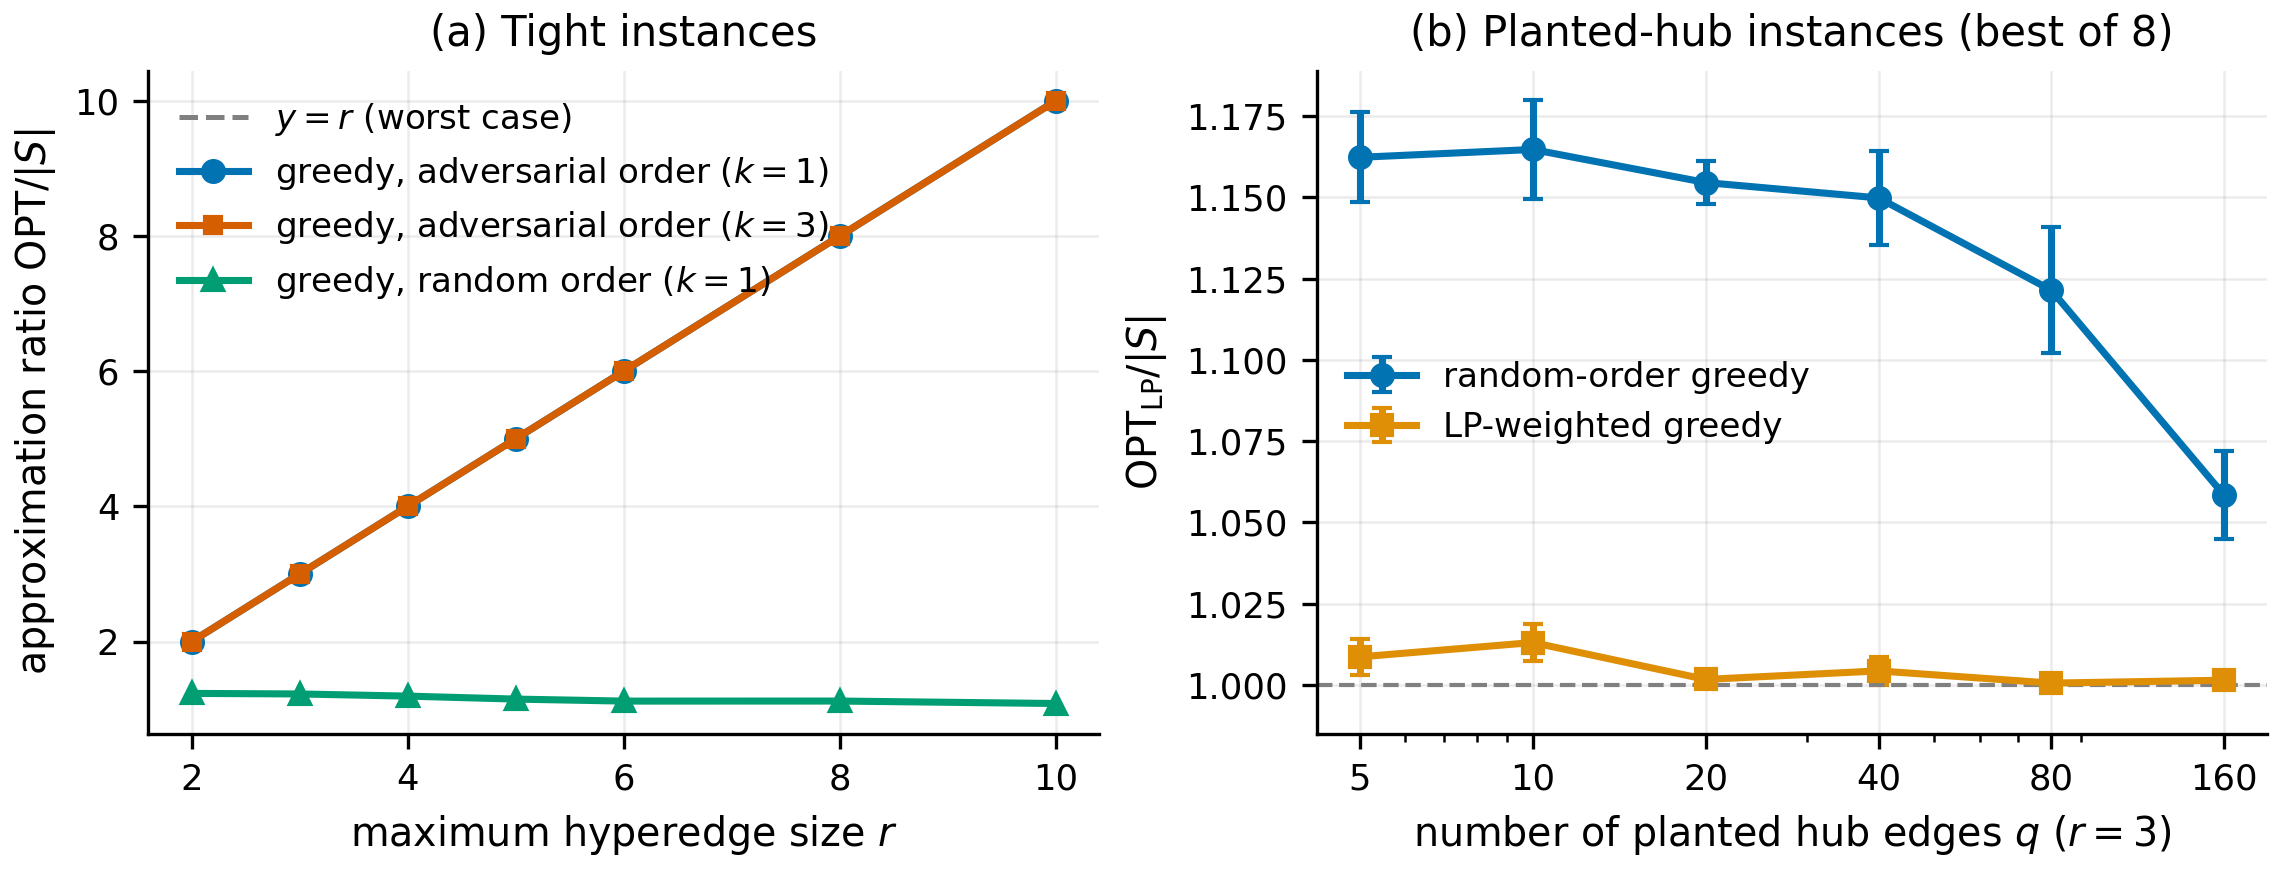

In [8]:
ax = axes[1]
for method, fmt, color, label in (
        ("greedy", "o-", COLORS[0], "random-order greedy"),
        ("lp_weighted", "s-", COLORS[1], "LP-weighted greedy")):
    ax.errorbar(planted_counts,
                [row[method]["mean"] for row in summary],
                yerr=[row[method]["std"] for row in summary],
                fmt=fmt, color=color, label=label, capsize=2.5)
ax.axhline(1, color="gray", linestyle="--", lw=1)
ax.set_xscale("log")
ax.set_xticks(planted_counts, labels=[str(x) for x in planted_counts])
ax.set_xlabel(r"number of planted hub edges $q$ ($r=3$)")
ax.set_ylabel(r"$\mathrm{OPT}_{\mathrm{LP}}/|S|$")
ax.set_ylim(bottom=0.985)
ax.set_title("(b) Planted-hub instances (best of 8)")
ax.legend()
save(fig, "expA_r_vs_delta", FIG)

plt.close(fig)
display(Image(filename=str(FIG / "expA_r_vs_delta.png"), width=950))

### 8. Figure 2, left: the Gaussian noise term

Experiment B fixes $n=1000$, $d=10$, $\varepsilon=1$, and $\delta=10^{-5}$. On the star, clustered, and matching families, the fixed-graph sensitivity is $2\Delta/n=2c$. The plotted quantity averages the squared Gaussian noise norm over 2,000 draws per point. Its expectation is

$$8\log(1.25/\delta)\,c^2d/\varepsilon^2.$$

The plot has no error bars or confidence intervals. It illustrates the noise calibration on these families. At large $c$, this untruncated noise term can exceed the error of a constant estimator, so the curve should not be read as the optimal error in that regime.

In [9]:
n, d, eps, delta = 1000, 10, 1.0, 1e-5
reps = 2000
families = [("star", 1.0, COLORS[3], "*")]
for kh in (2, 5, 10, 25, 50, 100, 250):
    families.append((f"clustered ({kh} hubs)", 1.0 / kh, COLORS[0], "o"))
families.append(("matching", 1.0 / n, COLORS[2], "s"))
assert [row[0] for row in families] == b["families"]
np.testing.assert_allclose([row[1] for row in families], b["c"], rtol=1e-12)
errs = b["err"]
expected_noise = 8 * np.log(1.25 / delta) * np.asarray(b["c"])**2 * d / eps**2
np.testing.assert_allclose(expected_noise, b["theory"], rtol=1e-12)
show_table(["Family", "c", "Monte Carlo mean", "Gaussian expectation"], [
    [name, density, f"{error:.6g}", f"{theory:.6g}"]
    for name, density, error, theory in zip(b["families"], b["c"], errs, b["theory"])
])

| Family | c | Monte Carlo mean | Gaussian expectation |
| --- | --- | --- | --- |
| star | 1.0 | 942.107 | 938.886 |
| clustered (2 hubs) | 0.5 | 232.615 | 234.721 |
| clustered (5 hubs) | 0.2 | 37.4432 | 37.5554 |
| clustered (10 hubs) | 0.1 | 9.37557 | 9.38886 |
| clustered (25 hubs) | 0.04 | 1.5112 | 1.50222 |
| clustered (50 hubs) | 0.02 | 0.370175 | 0.375554 |
| clustered (100 hubs) | 0.01 | 0.0949059 | 0.0938886 |
| clustered (250 hubs) | 0.004 | 0.0152178 | 0.0150222 |
| matching | 0.001 | 0.000944906 | 0.000938886 |

saved expB_density_parameter.pdf/.png


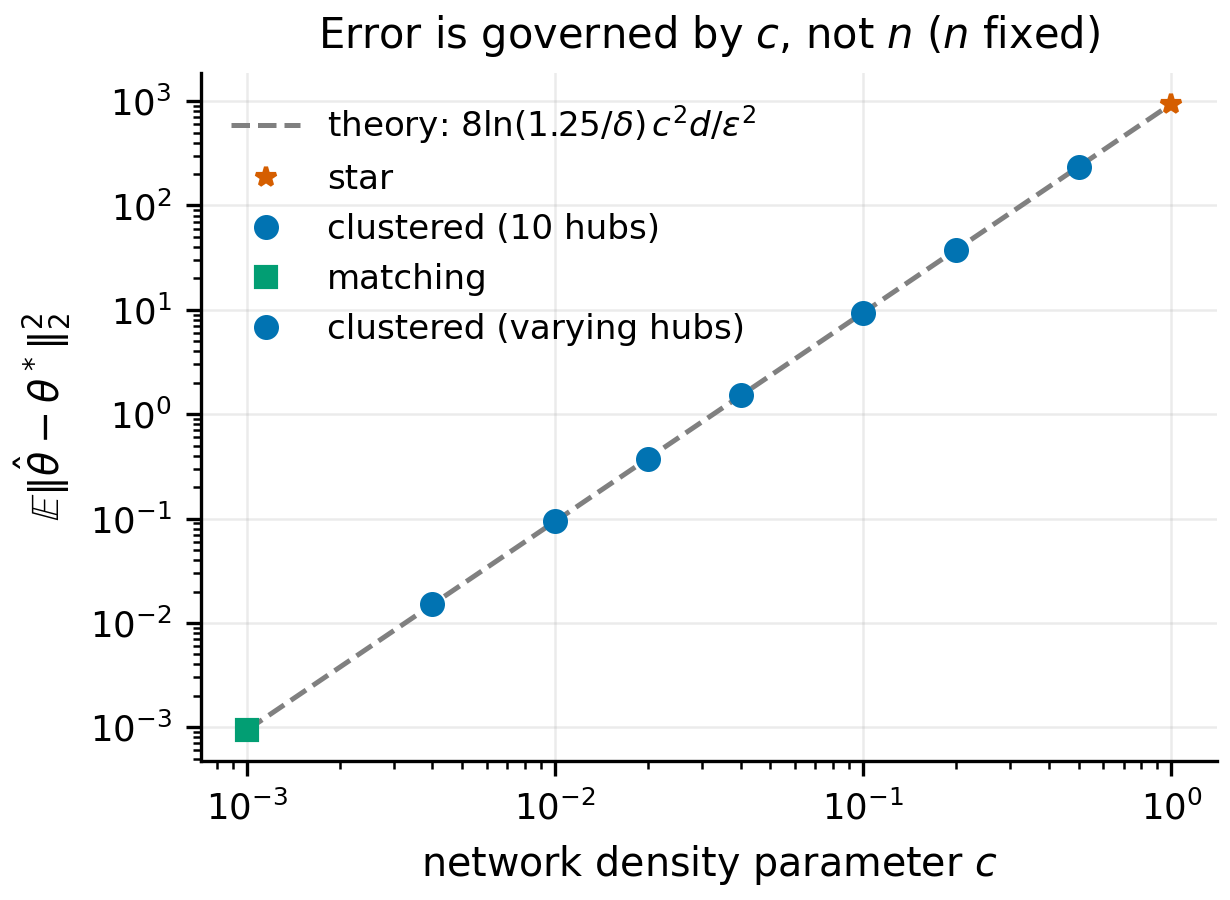

In [10]:
fig, ax = plt.subplots(figsize=(4.1, 3.0))
cgrid = np.logspace(np.log10(1.0 / n), 0, 50)
ax.plot(cgrid, 4 * cgrid ** 2 * 2 * np.log(1.25 / delta) * d / eps ** 2,
        "--", color="gray", lw=1.2,
        label=r"theory: $8\ln(1.25/\delta)\,c^2 d/\varepsilon^2$")
for (name, c, col, mk), e in zip(families, errs):
    lbl = name if ("hubs)" not in name or "10 hubs" in name) else None
    if "hubs" in name and lbl is None:
        lbl = None
    ax.plot([c], [e], mk, color=col, label=lbl if lbl else None)
ax.plot([], [], "o", color=COLORS[0], label="clustered (varying hubs)")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"network density parameter $c$")
ax.set_ylabel(r"$\mathbb{E}\|\hat\theta-\theta^*\|_2^2$")
ax.set_title(r"Error is governed by $c$, not $n$ ($n$ fixed)")
handles, labels = ax.get_legend_handles_labels()
seen, H, L = set(), [], []
for h, l in zip(handles, labels):
    if l and l not in seen:
        seen.add(l); H.append(h); L.append(l)
ax.legend(H, L, loc="upper left")
save(fig, "expB_density_parameter", FIG)

plt.close(fig)
display(Image(filename=str(FIG / "expB_density_parameter.png"), width=600))

### 9. Figure 2, right: testing on clustered networks

Experiment C runs the group-based test under the first Bernoulli hypothesis. Each group contains 400 samples, $\beta=0.24/\sqrt{400}$, and the experiment uses six group counts at each of three privacy levels. Every point estimates an error probability using 100,000 independent trials. The horizontal coordinate is $\varepsilon\beta\sqrt{nk}/4$, where $k$ is the number of groups and $n=400k$.

The dashed exponential is a reference for the privacy-noise term. The full finite-sample bound also has a sampling term. No confidence intervals or error bars are displayed. An empirical error below $10^{-5}$ is displayed at that Monte Carlo resolution; a zero observed count does not establish zero true error.

In [11]:
n_i, C2, T = 400, 0.24, 100_000
beta = C2 / np.sqrt(n_i)
epss = [0.15, 0.3, 0.6]
khs = [10, 25, 50, 100, 150, 220]
rows = testing_results
assert len(rows) == len(epss) * len(khs)
for row in rows:
    assert row["T"] == T
    np.testing.assert_allclose(row["x"], row["eps"] * beta * np.sqrt(n_i * row["kh"]**2) / 4,
                               rtol=1e-12)
show_table(["Privacy ε", "Groups k", "Recorded error", "Plot x-coordinate"], [
    [row["eps"], row["kh"], f'{row["err"]:.5f}', f'{row["x"]:.3f}'] for row in rows
])

| Privacy ε | Groups k | Recorded error | Plot x-coordinate |
| --- | --- | --- | --- |
| 0.15 | 10 | 0.39969 | 0.090 |
| 0.15 | 25 | 0.28451 | 0.225 |
| 0.15 | 50 | 0.16258 | 0.450 |
| 0.15 | 100 | 0.05342 | 0.900 |
| 0.15 | 150 | 0.01740 | 1.350 |
| 0.15 | 220 | 0.00362 | 1.980 |
| 0.3 | 10 | 0.32810 | 0.180 |
| 0.3 | 25 | 0.18292 | 0.450 |
| 0.3 | 50 | 0.06699 | 0.900 |
| 0.3 | 100 | 0.00983 | 1.800 |
| 0.3 | 150 | 0.00155 | 2.700 |
| 0.3 | 220 | 0.00009 | 3.960 |
| 0.6 | 10 | 0.24794 | 0.360 |
| 0.6 | 25 | 0.09926 | 0.900 |
| 0.6 | 50 | 0.02301 | 1.800 |
| 0.6 | 100 | 0.00122 | 3.600 |
| 0.6 | 150 | 0.00008 | 5.400 |
| 0.6 | 220 | 0.00000 | 7.920 |

saved expC_iid_testing.pdf/.png


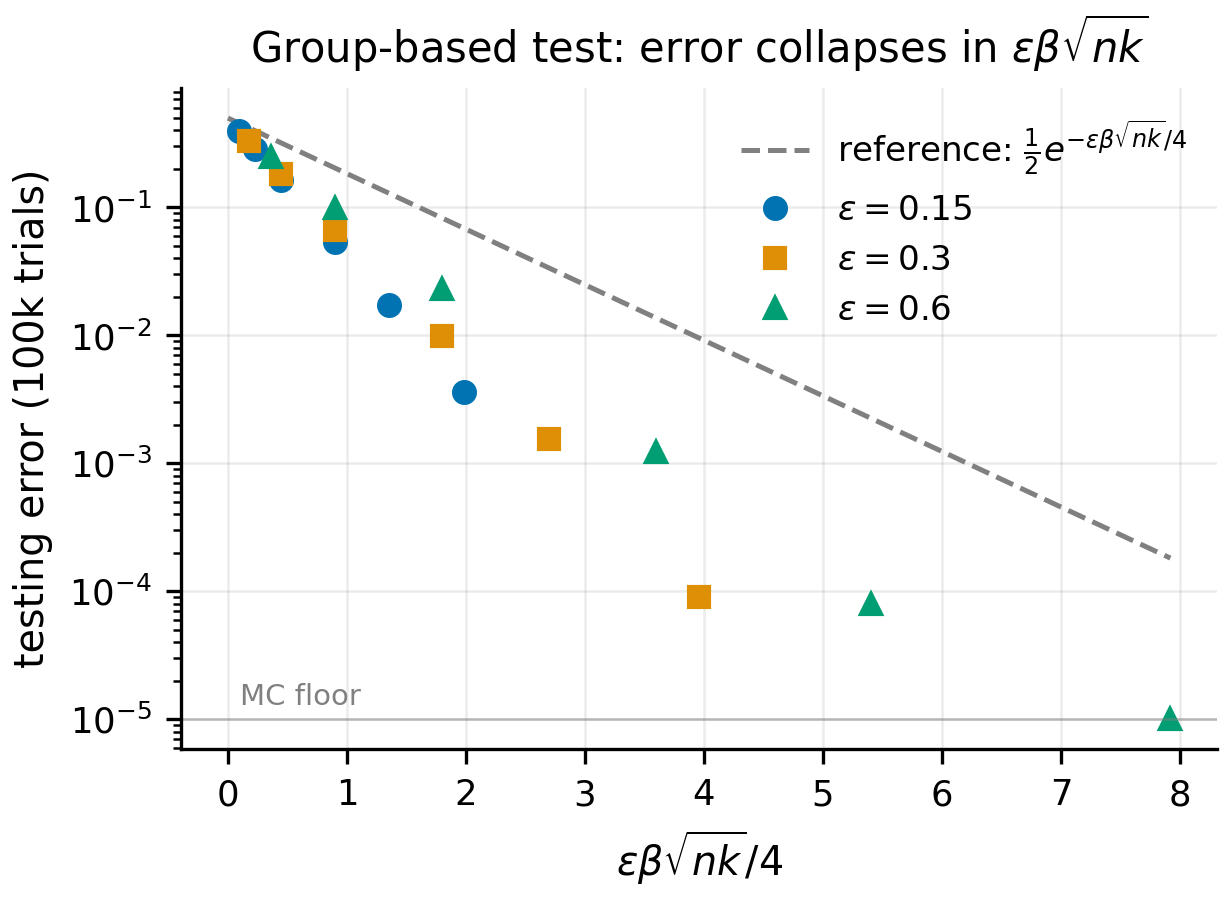

In [12]:
fig, ax = plt.subplots(figsize=(4.1, 3.0))
floor = 1.0 / 100_000
xg = np.linspace(0, max(r["x"] for r in rows), 100)
ax.plot(xg, 0.5 * np.exp(-xg), "--", color="gray", lw=1.2,
        label=r"reference: $\frac{1}{2}e^{-\varepsilon\beta\sqrt{nk}/4}$")
for eps, mk, col in zip(epss, "os^", COLORS):
    xs = [r["x"] for r in rows if r["eps"] == eps]
    ys = [max(r["err"], floor) for r in rows if r["eps"] == eps]
    ax.plot(xs, ys, mk, color=col, label=rf"$\varepsilon={eps}$")
ax.set_yscale("log")
ax.set_xlabel(r"$\varepsilon\beta\sqrt{nk}/4$")
ax.set_ylabel("testing error (100k trials)")
ax.set_title("Group-based test: error collapses in " + r"$\varepsilon\beta\sqrt{nk}$")
ax.axhline(floor, color="gray", lw=0.6, alpha=0.5)
ax.text(0.1, floor * 1.3, "MC floor", fontsize=7, color="gray")
ax.legend()
save(fig, "expC_iid_testing", FIG)

plt.close(fig)
display(Image(filename=str(FIG / "expC_iid_testing.png"), width=600))

### 10. Optional: rerun the experiments from their seeds

The plots above were regenerated from the included numerical results. To repeat the computations as well, set `RUN_FULL_EXPERIMENTS = True` below and run this section. The notebook copies the original scripts, benchmark data, and reference results into `notebook_outputs/rerun/`, then runs each script in a separate Python process. Experiment C has the largest Monte Carlo workload and will take longer than the other two.

The new numerical results and plots remain in that directory. Each rerun is compared with the supplied results; runtime measurements are excluded because they depend on the machine. Exact retained sets can depend on the LP solver's choice among optimal solutions. A numerical mismatch is reported so it can be inspected, rather than silently replacing the recorded result.

In [13]:
RUN_FULL_EXPERIMENTS = False
RERUN = OUTPUT / "rerun"

if RUN_FULL_EXPERIMENTS:
    RERUN.mkdir(parents=True, exist_ok=True)
    (RERUN / "figures").mkdir(exist_ok=True)
    (RERUN / "code").mkdir(exist_ok=True)
    for path in CODE.glob("*.py"):
        shutil.copy2(path, RERUN / "code" / path.name)
    shutil.copy2(ROOT / "requirements.txt", RERUN / "requirements.txt")
    for directory in ("data", "results"):
        shutil.copytree(ROOT / directory, RERUN / directory, dirs_exist_ok=True)
    print("Full reruns enabled; working directory:", RERUN.relative_to(ROOT))
else:
    print("Using the recorded results. Set RUN_FULL_EXPERIMENTS=True to recompute them.")

def numerical_match(expected, actual):
    if isinstance(expected, dict):
        return (isinstance(actual, dict) and expected.keys() == actual.keys()
                and all(numerical_match(expected[key], actual[key]) for key in expected))
    if isinstance(expected, list):
        return (isinstance(actual, list) and len(expected) == len(actual)
                and all(numerical_match(x, y) for x, y in zip(expected, actual)))
    if isinstance(expected, (int, float)) and not isinstance(expected, bool):
        return isinstance(actual, (int, float)) and bool(np.isclose(expected, actual, rtol=1e-10, atol=1e-12))
    return expected == actual

def rerun_experiment(script, result_name, figure_name):
    if not RUN_FULL_EXPERIMENTS:
        print(f"Skipped {script}; recorded-result regeneration is complete above.")
        return
    started = time.perf_counter()
    run = subprocess.run([sys.executable, str(RERUN / "code" / script)], cwd=RERUN,
                         text=True, capture_output=True)
    log_path = RERUN / (Path(script).stem + ".log")
    log_path.write_text(run.stdout + "\n" + run.stderr)
    if run.returncode:
        raise RuntimeError(f"{script} failed. See {log_path}\n{run.stderr[-2500:]}")
    matched = numerical_match(load_json(RESULTS / result_name),
                              load_json(RERUN / "results" / result_name))
    print(f"{script}: {time.perf_counter() - started:.1f} seconds")
    print("Numerical results match the recorded values:", matched)
    print("Full output log:", log_path.relative_to(ROOT))
    if not matched:
        print("Inspect the result JSON files and software versions before drawing conclusions.")
    display(Image(filename=str(RERUN / "figures" / (figure_name + ".png")), width=800))

Using the recorded results. Set RUN_FULL_EXPERIMENTS=True to recompute them.


**Rerun A.** This recomputes the tight-instance averages and the best-of-eight comparison on all 36 frozen planted-hub graphs. The LP and traversal timings are recorded separately in `exp_A_runtime.json`.

In [14]:
rerun_experiment("exp_A_approx.py", "exp_A.json", "expA_r_vs_delta")

Skipped exp_A_approx.py; recorded-result regeneration is complete above.


**Rerun B.** This repeats the Gaussian-noise experiment using 2,000 draws per network family.

In [15]:
rerun_experiment("exp_B_density.py", "exp_B.json", "expB_density_parameter")

Skipped exp_B_density.py; recorded-result regeneration is complete above.


**Rerun C.** This repeats the 100,000 testing trials at each of the 18 parameter settings. To regenerate only this plot outside the notebook, the original script also accepts `python code/exp_C_testing.py --plot-only` from the repository root.

In [16]:
rerun_experiment("exp_C_testing.py", "exp_C.json", "expC_iid_testing")

Skipped exp_C_testing.py; recorded-result regeneration is complete above.


### 11. Locate the outputs and verify the inputs

The three PDF assets below are the files used to assemble Figures 1 and 2 in the paper; the PNG copies are convenient for inspection. The final check verifies that the existing scripts, inputs, recorded results, and released figures have not changed during this notebook run. A small manifest records the environment and input hashes alongside the notebook outputs.

In [17]:
expected_figures = ["expA_r_vs_delta", "expB_density_parameter", "expC_iid_testing"]
for name in expected_figures:
    for suffix in (".pdf", ".png"):
        assert (FIG / (name + suffix)).is_file()
show_table(["File", "Bytes"], [[str(p.relative_to(ROOT)), p.stat().st_size]
                               for p in sorted(FIG.iterdir()) if p.suffix in (".pdf", ".png")])
changed = [name for name, before in original_hashes.items() if digest(ROOT / name) != before]
assert not changed, f"Original input files changed: {changed}"
manifest = {"software_versions": versions, "source_sha256": original_hashes,
            "regenerated_figures": [str((FIG / (name + ".pdf")).relative_to(ROOT))
                                    for name in expected_figures],
            "full_experiments_requested": RUN_FULL_EXPERIMENTS}
(OUTPUT / "manifest.json").write_text(json.dumps(manifest, indent=2))
print("All original scripts, inputs, results, and released figures are unchanged.")
print("Manifest:", (OUTPUT / "manifest.json").relative_to(ROOT))

All original scripts, inputs, results, and released figures are unchanged.
Manifest: notebook_outputs/manifest.json


| File | Bytes |
| --- | --- |
| notebook_outputs/figures/expA_r_vs_delta.pdf | 23862 |
| notebook_outputs/figures/expA_r_vs_delta.png | 184426 |
| notebook_outputs/figures/expB_density_parameter.pdf | 25712 |
| notebook_outputs/figures/expB_density_parameter.png | 97471 |
| notebook_outputs/figures/expC_iid_testing.pdf | 24522 |
| notebook_outputs/figures/expC_iid_testing.png | 92942 |